In [30]:
%pip install -q QuantLib numpy pandas scipy scikit-learn torch matplotlib

Note: you may need to restart the kernel to use updated packages.


In [31]:
import copy 
import json 
import random 
import time 
from pathlib import Path 
import numpy  as np 
import pandas as pd
import matplotlib.pyplot as plt
import QuantLib as ql 
import torch 
from torch import nn
from scipy.stats import qmc, norm 
from sklearn.preprocessing import StandardScaler

In [32]:
PILOT = False
FEATURES = ['S0', 'K', 'T', 'r', 'v0', 'kappa', 'theta', 'sigma', 'rho']
SHARED = FEATURES[3:]
BOUNDS = [
    (0.0, 0.1), 
    (0.05, 0.5), 
    (0.0, 2.0),
    (0.0, 0.5), 
    (0.0, 0.5), 
    (-0.95, 0.0)
]
TRAIN_N, VALIDATION_N, TEST_N = 2000, 200, 500
HIDDEN_UNITS = (128,128,128)
EPOCHS, PATIENCE, BATCH_SIZE, LEARNING_RATE, MIN_DELTA = 1000, 100, 64, 1e-3, 1e-7 
MODEL_SEED = (42,43,44)
INTEGRATION_ORDER, TIMING_N = 128, 20
if PILOT: 
    TRAIN_N, VALIDATION_N, TEST_N, EPOCHS, PATIENCE, TIMING_N = 64, 16, 20, 5, 3, 3
STRIKES = 1/np.linspace(1.4, 0.6, 7)
MATURITIES = np.rint(np.linspace(0.1,1.4,7)*365).astype(int)/365
MATURITIES[0] = 37/365
FULL_GRID = np.array([(K,T) for T in MATURITIES for K in STRIKES])
GRIDS = {
    3: [0, 3, 6], 
    5: [0, 1, 3, 5, 6], 
    7: list(range(7))
}
OUT = Path('experiment_scaling')/('pilot' if PILOT else 'full')
OUT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
valuation, dc = ql.Date(2, ql.January, 2026), ql.Actual365Fixed()
ql.Settings.instance().evaluationDate = valuation 
(OUT/'config.json').write_text(json.dumps(dict(features=FEATURES, 
    bounds=dict(zip(SHARED, BOUNDS)),
    scenarios=[TRAIN_N, VALIDATION_N, TEST_N], 
    data_seeds=[42, 43, 44], 
    model_seeds=MODEL_SEED,
    hidden_units=HIDDEN_UNITS, 
    epochs=EPOCHS, patience=PATIENCE, 
    batch_scenarios=BATCH_SIZE,
    learning_rate=LEARNING_RATE, 
    min_delta=MIN_DELTA, 
    integration_order=INTEGRATION_ORDER,
    grid=FULL_GRID.tolist(), 
    grid_indices=GRIDS, 
    timing_n = TIMING_N, 
    spot=1.0,
    dividend=0.0,
    torch_threads=1,
    activation='ReLU',
    optimizer='Adam', 
    loss='scaled residual MSE'), indent=2))

4131

In [37]:
print(OUT.resolve())
results = pd.read_csv(OUT / 'surface_trials.csv')
print(results[['model', 'seed', 'contracts']])

/Users/john.madhu_/Desktop/MSC_thesis/src/heston/experiment_scaling/full
                 model  seed  contracts
0     Pointwise Hybrid    44          9
1  Multi-output Hybrid    44          9
2     Pointwise Hybrid    44         25
3  Multi-output Hybrid    44         25
4     Pointwise Hybrid    44         49
5  Multi-output Hybrid    44         49
6     Pointwise Hybrid    42          9


In [33]:
def sample_params(n, seed): 
    lo, hi = np.array(BOUNDS).T
    return qmc.scale(qmc.LatinHypercube(d=len(SHARED), seed=seed).random(n), lo, hi)

def heston_surface(params, grid): 
    r, v0, kappa, theta, sigma, rho = map(float, params)
    rf = ql.YieldTermStructureHandle(ql.FlatForward(valuation, r, dc))
    div = ql.YieldTermStructureHandle(ql.FlatForward(valuation, 0.0, dc))
    spot = ql.QuoteHandle(ql.SimpleQuote(1.0))
    process = ql.HestonProcess(rf, div, spot, v0, kappa, theta, sigma, rho)
    engine = ql.AnalyticHestonEngine(ql.HestonModel(process), INTEGRATION_ORDER)
    price = []
    for K,T in grid: 
        option = ql.VanillaOption(ql.PlainVanillaPayoff(ql.Option.Call, float(K)),
                                  ql.EuropeanExercise(valuation + int(round(T*365))))
        option.setPricingEngine(engine)
        price.append(option.NPV())
    return np.array(price)

def heston_prices(params, grid): 
    return np.stack([heston_surface(p, grid) for p in params])

def contract_inputs(params, grid): 
    n, m = len(params), len(grid)
    return np.column_stack([np.ones(n * m), np.tile(grid, (n,1)), np.repeat(params, m, axis=0)])

def black_scholes_price(x):
    S, K, T, r, v0, kappa, theta = x[:, :7].T 
    a = kappa * T
    w = np.divide(-np.expm1(-a), a, out=np.ones_like(a), where=a!=0)
    v = theta + (v0 - theta) * w 
    vol_t = np.sqrt(v*T)
    d1 = (np.log(S/K) + (r+v/2) * T)/vol_t
    return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d1-vol_t)

def create_data(name, n, seed): 
    p = sample_params(n, seed)
    path = OUT/f'{name}_{n}_seed{seed}.npz'
    if path.exists():
        with np.load(path) as data: 
            if (np.array_equal(data['params'], p) and np.array_equal(data['grid'], FULL_GRID)
                and int(data['order']) == INTEGRATION_ORDER):
                return p, data['prices'], float(data['seconds'])
    start = time.perf_counter()
    y = heston_prices(p, FULL_GRID)
    elapsed = time.perf_counter() - start
    x = contract_inputs(p, FULL_GRID)
    lower = np.maximum(1-x[:,1]*np.exp(-x[:,3]*x[:,2]), 0)
    assert np.isfinite(y).all() and (y.ravel() >= lower-1e-4).all() and (y<= 1+1e-4).all()
    np.savez_compressed(path, params=p, grid=FULL_GRID, order=INTEGRATION_ORDER, prices=y, seconds=elapsed)
    print(f'{name}: {n} surfaces | {elapsed:2f}s', flush=True)
    return p, y, elapsed

In [34]:
train, y_train, t_train = create_data('train', TRAIN_N, 42)
validation, y_val, t_val = create_data('validation', VALIDATION_N, 43)
test, y_test, t_test = create_data('test', TEST_N, 44)
assert len(np.unique(np.vstack([train, validation, test]), axis=0)) == TRAIN_N + VALIDATION_N + TEST_N
pd.DataFrame({'split':['train', 'validation', 'test'], 'seconds':[t_train, t_val, t_test]}).to_csv(OUT / 'data_generation.csv', index=False)

In [35]:
class MLP(nn.Module): 
    def __init__(self, input_dim, output_dim):
        super().__init__()
        layers = []
        width = input_dim
        for hidden_width in HIDDEN_UNITS: 
            layers.extend([
                nn.Linear(width, hidden_width), 
                nn.ReLU()])
            width = hidden_width
        layers.append(nn.Linear(width, output_dim))
        self.net = nn.Sequential(*layers)
    def forward(self,x):
        return self.net(x)
    
def fit_mlp(Xtr, Rtr, Xva, Rva, seed):
    torch.manual_seed(seed)
    start = time.perf_counter()
    scaler = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[-1]))
    ym, ys = Rtr.mean(), Rtr.std() or 1. 
    def tensor(x):
        return torch.tensor(scaler.transform(x.reshape(-1, x.shape[-1])).reshape(x.shape), dtype=torch.float32)
    xtr, xva = tensor(Xtr), tensor(Xva)
    ytr, yva = [torch.tensor((y-ym)/ys, dtype=torch.float32) for y in (Rtr, Rva)]
    net = MLP(Xtr.shape[-1], 1 if Xtr.ndim==3 else Rtr.shape[1])
    optimizer, criterion = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE), nn.MSELoss()
    best_loss, best_state, stale = float('inf'), None, 0
    rng = torch.Generator().manual_seed(seed)
    for epoch in range(1, EPOCHS+1):
        net.train()
        for idx in torch.randperm(len(xtr), generator=rng).split(BATCH_SIZE):
            optimizer.zero_grad()
            loss = criterion(net(xtr[idx]).reshape_as(ytr[idx]), ytr[idx])
            loss.backward()
            optimizer.step()
        net.eval()
        with torch.inference_mode():
            val_loss = criterion(net(xva).reshape_as(yva), yva).item()
        if not np.isfinite(val_loss):
            raise RuntimeError('Non-finite validation loss')
        if val_loss < best_loss - MIN_DELTA: 
            best_loss, best_state, best_epoch, stale = val_loss, copy.deepcopy(net.state_dict()), epoch, 0
        else: 
            stale += 1
        if epoch % 100 == 0: 
            print(f'Epoch {epoch}: validation MSE={val_loss:.6g}', flush=True)
        if stale >= PATIENCE: 
            break
    net.load_state_dict(best_state)
    return (net.eval(), scaler, ym, ys), time.perf_counter() - start, best_epoch, epoch 

def predict(model, params, grid, multi): 
    net, scaler, ym, ys = model 
    x = contract_inputs(params, grid)
    inputs = params if multi else x 
    data = torch.tensor(scaler.transform(inputs), dtype=torch.float32)
    with torch.inference_mode():
        residual = np.concatenate([net(b).numpy() for b in data.split(512)])
    return black_scholes_price(x).reshape(len(params), -1) + (residual*ys+ym).reshape(len(params), -1)

def metrics(actual, pred):
    e = (pred - actual).ravel()
    ae = np.abs(e)
    return dict(mae=ae.mean(), rmse=np.sqrt(np.mean(e**2)), p90 = np.percentile(ae,90), max_error=ae.max(), r2 = 1 -np.sum(e**2)/np.sum((actual-actual.mean())**2))

def median_time(fn, repeats): 
    fn()
    times = []
    for _ in range(repeats): 
        start = time.perf_counter()
        result = fn()
        times.append(time.perf_counter()-start)
        assert np.isfinite(result).all()
    return np.median(times)


In [36]:
trial_path = OUT / 'surface_trials.csv'
results = pd.read_csv(trial_path).to_dict('records') if trial_path.exists() else []
assert 1 <= TIMING_N <= len(test)
keys = [(r['contracts'], r['model'], r['seed']) for r in results]
assert len(keys) == len(set(keys)), 'Duplicate trial rows'
for size, idx in GRIDS.items():
    ids = [i*7 + j for i in idx for j in idx]
    grid, m = FULL_GRID[ids], len(ids)
    Ytr, Yva, Yte = y_train[:,ids], y_val[:,ids], y_test[:,ids]
    Xtr = contract_inputs(train, grid)
    Xva = contract_inputs(validation, grid)
    Rtr = Ytr-black_scholes_price(Xtr).reshape(Ytr.shape)
    Rva = Yva - black_scholes_price(Xva).reshape(Yva.shape)
    q1, qb = [
        median_time(lambda p = test[:n]: heston_prices(p,grid), 3) 
        for n in (1, TIMING_N)
    ]
    for name, multi in [
        ('Pointwise Hybrid', False), 
        ('Multi-output Hybrid', True)
    ]:
        for seed in MODEL_SEED:
            stem = f'{size}x{size}_{name.split()[0]}_seed{seed}' 
            checkpoint = OUT/f'{stem}.pt'
            if (m, name, seed) in keys: 
                assert checkpoint.exists(), f'Missing Checkpoint: {checkpoint}'
                print(f'Skipping completed {stem}', flush=True)
                continue
            model, seconds, best_epoch, epochs = fit_mlp(
                train if multi else Xtr.reshape(TRAIN_N, m, -1), 
                Rtr, 
                validation if multi else Xva.reshape(VALIDATION_N, m, -1),
                Rva, 
                seed 
            )
            pred = predict(model, test, grid, multi)
            val = predict(model, validation, grid, multi)
            t1, tb = [
                median_time(
                    lambda p = test[:n]:predict(model,p,grid,multi), 7
                ) for n in (1, TIMING_N)
            ]
            record = dict(
                model=name, 
                seed=seed,
                contracts=m,
                training_labels=TRAIN_N*m,
                **metrics(Yte, pred), 
                validation_mae=metrics(Yva, val)['mae'],
                training_seconds=seconds,
                best_epoch = best_epoch,
                epochs=epochs,
                updates=epochs*int(np.ceil(TRAIN_N/BATCH_SIZE)),
                parameters = sum(p.numel() for p in model[0].parameters()),
                latency_ms=1000*t1,
                batch_ms_per_surface = 1000 * tb/TIMING_N,
                quantlib_latency_ms=1000*q1,
                quantlib_batch_ms_per_surface = 1000 * qb / TIMING_N, 
                speedup_single=q1/t1,
                speedup_batch=qb/tb,
            )
            net, scaler, ym, ys = model
            torch.save(dict(
                model_state_dict = net.state_dict(), 
                hidden_units = HIDDEN_UNITS,
                features=SHARED if multi else FEATURES, 
                grid = grid, 
                x_mean=scaler.mean_,
                x_scale = scaler.scale_, 
                y_mean = ym, 
                y_scale = ys, 
                target='residual', 
                actual=Yte,
                predicted=pred
            ), checkpoint)
            np.savez_compressed(OUT/f'{stem}_predictions.npz', params=test, grid=grid, actual=Yte, predicted=pred)
            results.append(record)
            tmp = trial_path.with_suffix('.tmp')
            pd.DataFrame(results).to_csv(tmp, index=False)
            tmp.replace(trial_path)
            print(
                f'{stem}: MAE={record["mae"]:.6g},' 
                f'speedup={qb/tb:.1f}x,'
                f'train={seconds:.1f}s', 
                flush=True
            )
trials = pd.DataFrame(results)
expected = {
    (m, name, seed) 
    for m in (9,25,49)
    for name in ('Pointwise Hybrid', 'Multi-output Hybrid') 
    for seed in MODEL_SEED
}
assert set(zip(trials.contracts, trials.model, trials.seed)) == expected
assert len(trials) == len(expected)
summary = trials.groupby(['contracts', 'model']).agg({
    c:['mean', 'std'] 
    for c in trials.select_dtypes('number') 
    if c not in ['contracts', 'seed']
})
summary.columns= ['_'.join(c) for c in summary.columns]
summary = summary.reset_index()
summary.to_csv(OUT/'surface_summary.csv', index=False)
print(summary[[
    'contracts', 
    'model', 
    'mae_mean', 
    'rmse_mean', 
    'latency_ms_mean', 
    'speedup_batch_mean'
]].to_string(index=False))

Epoch 100: validation MSE=0.00194534
Epoch 200: validation MSE=0.00114675
Epoch 300: validation MSE=0.00122664
Epoch 400: validation MSE=0.00116712
Epoch 500: validation MSE=0.000969022
Epoch 600: validation MSE=0.00102488
Epoch 700: validation MSE=0.000941808
Epoch 800: validation MSE=0.0010465
3x3_Pointwise_seed42: MAE=5.55469e-05,speedup=14.8x,train=156.6s
Epoch 100: validation MSE=0.00220654
Epoch 200: validation MSE=0.0012967
Epoch 300: validation MSE=0.0014083


KeyboardInterrupt: 

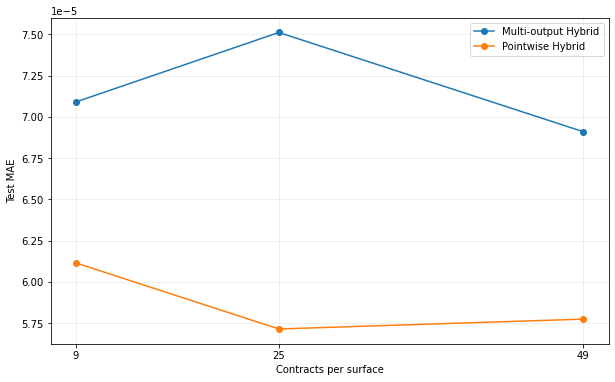

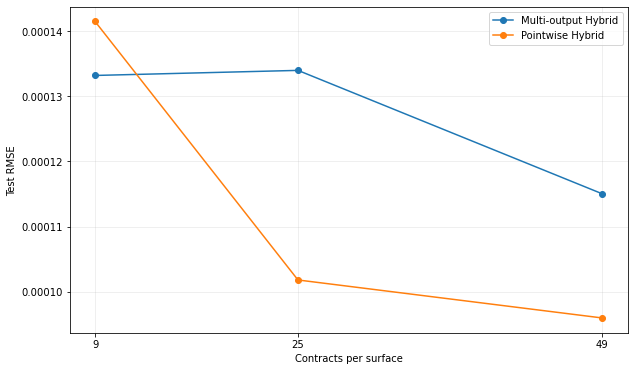

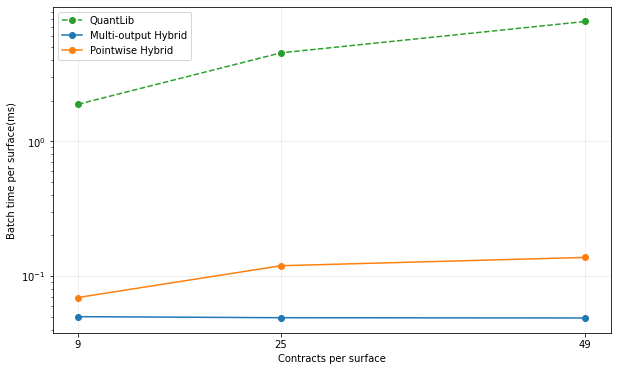

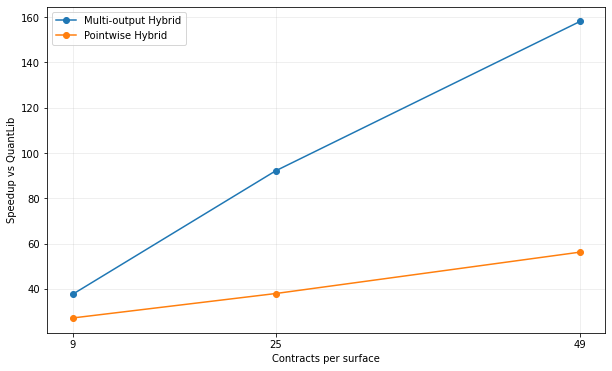

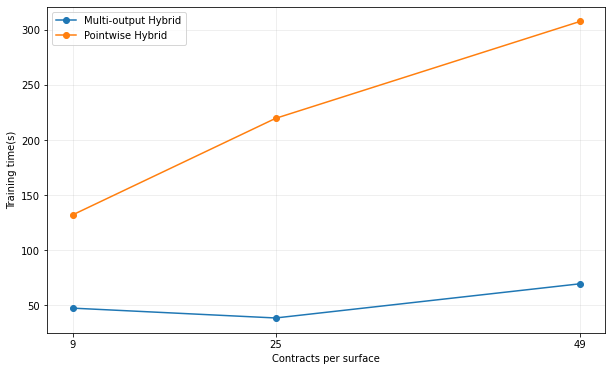

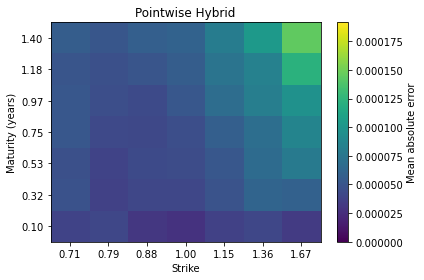

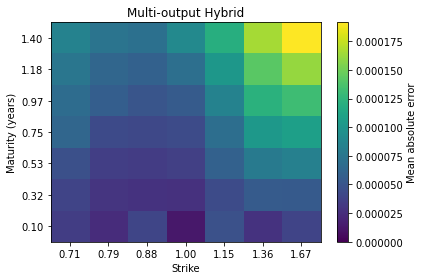

In [ ]:
heatmaps = {}
for name in ('Pointwise Hybrid', 'Multi-output Hybrid'): 
    for seed in MODEL_SEED: 
        stem = f'7x7_{name.split()[0]}_seed{seed}'
        try: 
            saved = torch.load(OUT/f'{stem}.pt', map_location='cpu', weights_only=False)
        except TypeError:
            saved = torch.load(OUT/f'{stem}.pt', map_location='cpu')
        assert np.array_equal(saved['grid'], FULL_GRID)
        if 'actual' in saved and 'predicted' in saved:
            actual, pred = saved['actual'], saved['predicted']
        else:
            with np.load(OUT/f'{stem}_predictions.npz') as data:
                actual, pred = data['actual'], data['predicted']
        assert np.array_equal(actual, y_test) and pred.shape == actual.shape
        heatmaps.setdefault(name,[]).append(np.abs(pred-actual).mean(axis=0).reshape(7,7))
for metric, label in [
    ('mae', 'Test MAE'), 
    ('rmse', 'Test RMSE'), 
    ('batch_ms_per_surface', 'Batch time per surface(ms)'),
    ('speedup_batch', 'Speedup vs QuantLib'),
    ('training_seconds', 'Training time(s)')] : 
    fig, ax = plt.subplots(figsize=(10,6))
    for name, g in summary.groupby('model'): 
        ax.errorbar(
            g.contracts.to_numpy(), 
            g[f'{metric}_mean'].to_numpy(), 
            yerr=g[f'{metric}_std'].to_numpy() if len(MODEL_SEED) > 1 else None, 
            marker='o', 
            capsize=3, 
            label=name
        )
    if metric == 'batch_ms_per_surface': 
        g = summary.drop_duplicates('contracts')
        ax.plot(
            g.contracts.to_numpy(), 
            g.quantlib_batch_ms_per_surface_mean.to_numpy(), 
            'o--', 
            label='QuantLib'
        )
        ax.set_yscale('log')
    ax.set(xlabel='Contracts per surface', ylabel=label, xticks=[9,25,49])
    ax.grid(alpha=0.25)
    ax.legend()
    fig.savefig(OUT/f'{metric}.png', dpi=220)
    plt.show()
    plt.close(fig)
errors = {name:np.mean(values,axis=0) for name, values in heatmaps.items()}
for name, error in errors.items(): 
    fig, ax = plt.subplots(figsize=(6,4))
    im = ax.imshow(
        error, 
        origin='lower', 
        aspect='auto', 
        vmin=0,
        vmax=max(e.max() for e in errors.values()))
    ax.set(title=name, xlabel='Strike', ylabel='Maturity (years)', xticks=range(7), yticks=range(7),
           xticklabels=[f'{k:.2f}' for k in STRIKES], yticklabels=[f'{t:.2f}' for t in MATURITIES])
    fig.colorbar(im, ax=ax, label='Mean absolute error')
    fig.tight_layout()
    fig.savefig(OUT / f'{name.split()[0]}_heatmap.png', dpi=220)
    plt.show()
    plt.close(fig)    